# Appendix: visual examples -- soft GT vs. our estimate vs. GDino alone

For detections with a matched soft-GT box, compares three class-probability
distributions side by side: the soft ground truth, our method's estimate
(PLS+Bayes at 100% budget with the best-AP grid-search hyperparameters, as in the
AP curves of `annotation_benchmark_results.ipynb`), and GDino alone (the calibrated
baseline, no propagation). Examples are grouped by whether our estimate's argmax
class **agrees** or **disagrees** with GDino's.

In [1]:
import os
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

sys.path.append("../utils")
from plot_layout import set_plot_layout
set_plot_layout(path_to_latex="/home/klees/texlive/2024/bin/x86_64-linux")

sys.path.append("../label_spreading")
from src import label_spreading_object_conventional
from baseline_comparison import calibrated_gdino_baseline, build_bayes_dataset, sample_budget_indices

os.makedirs("plots/examples", exist_ok=True)

SCORE_THR = 0.2
ONLY_OBJECTS = False
DATA_SPACE = "gdino_embedding"
AMGX_CONFIG = "../label_spreading/configs/FGMRES_AGGREGATION.json"
SOFT_GT_PATH = "../data/soft_datasets/soft_COCO_2017_val.json"
GRID_RESULTS_CSV = ("../analysis/experiments/coco_val_baseline_comp_simple/grid_search/"
                     "coco_val_baseline_comp_simple_grid_search_results.csv")
GRID_SEED = 42
COCO_IMAGES_DIR = "/home/klees/SoftTeacher/data/coco/val2017"
BUDGET = 1.00   # 100% budget

with open(SOFT_GT_PATH) as f:
    soft_gt_json = json.load(f)
CLASS_NAMES = [c["name"] for c in soft_gt_json["categories"]] + ["background"]
IMAGE_FILENAME = {img["id"]: img["file_name"] for img in soft_gt_json["images"]}
IMAGE_WH = {img["id"]: (img["width"], img["height"]) for img in soft_gt_json["images"]}

df_full = pd.read_parquet("../data/matched_dataset/coco_val_matched.parquet")
dataset = df_full[df_full["gdino_score"] >= SCORE_THR].copy().reset_index(drop=True)
sl = np.array([v for v in dataset["soft_label"].values])
dataset["soft_label"] = list(sl)
dataset["is_object"] = dataset["gdino_match"].astype(float)
# box_frac: detection box area as a fraction of its image -- used to bias example
# selection toward visually legible boxes (some detections are legitimately tiny,
# e.g. a small watermark/logo or a distant object, which is fine data but a poor
# illustrative figure at whole-image scale).
img_wh = np.array([IMAGE_WH[iid] for iid in dataset["image_id"]])
boxes = np.vstack(dataset["gdino_bbox"].to_numpy())
box_area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
dataset["box_frac"] = box_area / (img_wh[:, 0] * img_wh[:, 1])
print(f"{len(dataset):,} detections (score >= {SCORE_THR})")

grid_results = pd.read_csv(GRID_RESULTS_CSV)

/home/klees/miniconda3/envs/label_spreading/lib/python3.11/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


85,991 detections (score >= 0.2)


In [2]:
def winning_hp(method, budget, metric="AP"):
    sub = grid_results[(grid_results["method"] == method) & (np.isclose(grid_results["budget"], budget))]
    return sub.loc[sub[metric].idxmax()]

indices_b = sample_budget_indices(len(dataset), BUDGET, seed=GRID_SEED)
n_samples_b = len(indices_b)

baseline_row = winning_hp("Baseline", BUDGET)   # no hyperparameter, row just carries the metrics
baseline_ds, p_hat_baseline_b = calibrated_gdino_baseline(dataset, df_full, BUDGET, "viz_baseline",
                                                            ONLY_OBJECTS, DATA_SPACE)

bayes_row = winning_hp("Bayes", BUDGET)
pls_ds = label_spreading_object_conventional(
    "viz_pls", ONLY_OBJECTS, dataset.copy(), DATA_SPACE, "label", "soft_label", "is_object", "all",
    int(bayes_row["k"]), bayes_row["alpha"], n_samples_b, indices=indices_b, config=AMGX_CONFIG,
    bandwidth_scale=bayes_row["bandwidth_scale"],
)
pls_trials = pls_ds["trials"].to_numpy()
pls_p_hat = np.vstack(pls_ds["p_hat"].to_numpy())
F_pls = pls_p_hat * pls_trials[:, None]
bayes_ds = build_bayes_dataset(bayes_row["kappa"], p_hat_baseline_b, F_pls, pls_ds, "viz_bayes",
                                int(bayes_row["k"]), bayes_row["alpha"], n_samples_b,
                                ONLY_OBJECTS, DATA_SPACE, AMGX_CONFIG)
print(f"Bayes winning combo (100% budget, best AP): k={int(bayes_row['k'])} alpha={bayes_row['alpha']} "
      f"bandwidth={bayes_row['bandwidth_scale']} kappa={bayes_row['kappa']}")

our_p_hat = np.vstack(bayes_ds["p_hat"].to_numpy())
gdino_p_hat = np.vstack(baseline_ds["p_hat"].to_numpy())
gt_soft = np.vstack(dataset["soft_label"].to_numpy())

our_pred = our_p_hat.argmax(axis=1)
gdino_pred = gdino_p_hat.argmax(axis=1)
gt_pred = gt_soft.argmax(axis=1)
matched = dataset["gdino_match"].astype(bool).to_numpy()

agree_mask = matched & (our_pred == gdino_pred)
disagree_mask = matched & (our_pred != gdino_pred)
print(f"Matched detections: {matched.sum():,}")
print(f"  agreement (our argmax == GDino argmax):    {agree_mask.sum():,}")
print(f"  disagreement (our argmax != GDino argmax): {disagree_mask.sum():,}")

use pre-defined indices


Bayes winning combo (100% budget, best AP): k=20 alpha=0.2 bandwidth=0.5 kappa=1.0
Matched detections: 39,586
  agreement (our argmax == GDino argmax):    31,554
  disagreement (our argmax != GDino argmax): 8,032


## Example selection

**Agreement**: highest-confidence cases where our estimate and GDino agree with each other AND with the soft-GT argmax. **Disagreement**: up to `N_EXAMPLES - 1` cases where our estimate matches the soft-GT argmax but GDino's doesn't (our method correcting GDino); the remaining slot(s) are filled with the reverse case (GDino right, ours wrong).

**Uncertain GT**: cases where the soft ground truth itself is not confident (max class probability < 0.9), i.e. genuine label ambiguity rather than a single correct answer. Ranked by ascending GT confidence (most ambiguous first).

All buckets prefer boxes covering at least 2% of the image so examples stay legible at whole-image scale.

In [3]:
N_EXAMPLES = 4
MIN_BOX_FRAC = 0.02   # require at least ~2% of the image -- keeps examples legible at
                       # whole-image display scale; relaxed automatically per-bucket if
                       # that leaves too few candidates to pick N_EXAMPLES from.
box_frac = dataset["box_frac"].to_numpy()


def top_k_legible(mask, conf, k, min_frac=MIN_BOX_FRAC, label=""):
    """Top-k row indices by conf among mask, restricted to box_frac >= min_frac
    where possible -- halves min_frac until enough candidates exist (or gives up and
    uses the unfiltered mask), so a bucket with few legitimate candidates still fills
    rather than coming up short."""
    frac = min_frac
    while frac > 0:
        candidates = np.where(mask & (box_frac >= frac))[0]
        if len(candidates) >= k:
            if frac < min_frac:
                print(f"  [{label}] relaxed min_frac to {frac:.4f} ({len(candidates)} candidates)")
            return candidates[np.argsort(-conf[candidates])][:k]
        frac /= 2
    candidates = np.where(mask)[0]
    print(f"  [{label}] gave up on box_frac filter entirely ({len(candidates)} candidates)")
    return candidates[np.argsort(-conf[candidates])][:k]


# Agreement: our_pred == gdino_pred == gt_pred, ranked by our confidence in that class
agree_correct = agree_mask & (our_pred == gt_pred)
agree_conf = our_p_hat[np.arange(len(dataset)), our_pred]
agree_examples = top_k_legible(agree_correct, agree_conf, N_EXAMPLES, label="agree")

# Disagreement: up to N_EXAMPLES-1 "we fixed GDino's mistake" (our_pred == gt_pred != gdino_pred),
# remaining slots filled with "GDino was right, we were wrong".
we_fixed = disagree_mask & (our_pred == gt_pred) & (gdino_pred != gt_pred)
gdino_right = disagree_mask & (gdino_pred == gt_pred) & (our_pred != gt_pred)
we_fixed_conf = our_p_hat[np.arange(len(dataset)), our_pred]
n_fixed_target = min(N_EXAMPLES - 1, int(we_fixed.sum()))
we_fixed_sorted = top_k_legible(we_fixed, we_fixed_conf, max(n_fixed_target, 0), label="we_fixed") \
    if n_fixed_target > 0 else np.array([], dtype=int)
n_fixed = len(we_fixed_sorted)
n_gdino_right = min(N_EXAMPLES - n_fixed, int(gdino_right.sum()))
gdino_right_sorted = top_k_legible(gdino_right, we_fixed_conf, n_gdino_right, label="gdino_right") \
    if n_gdino_right > 0 else np.array([], dtype=int)
disagree_examples = np.concatenate([we_fixed_sorted, gdino_right_sorted]).astype(int)

print(f"Agreement examples (row indices): {agree_examples.tolist()}")
print(f"Disagreement examples (row indices): {disagree_examples.tolist()}  "
      f"({n_fixed} 'we fixed GDino', {len(gdino_right_sorted)} 'GDino was right')")

Agreement examples (row indices): [34341, 61439, 66045, 46144]
Disagreement examples (row indices): [58465, 60558, 15029, 10397]  (3 'we fixed GDino', 1 'GDino was right')


In [4]:
UNCERTAIN_GT_MAX_PROB = 0.9
gt_max_prob = gt_soft.max(axis=1)
uncertain_gt_mask = matched & (gt_max_prob < UNCERTAIN_GT_MAX_PROB)
uncertain_gt_examples = top_k_legible(uncertain_gt_mask, -gt_max_prob, N_EXAMPLES, label="uncertain_gt")

print(f"Uncertain-GT examples (row indices): {uncertain_gt_examples.tolist()}")
for idx in uncertain_gt_examples:
    top2 = np.argsort(-gt_soft[idx])[:2]
    top2_str = ", ".join(f"{CLASS_NAMES[c]}={gt_soft[idx][c]:.2f}" for c in top2)
    print(f"  row={idx}  gt_max={gt_max_prob[idx]:.3f}  top2: {top2_str}")

Uncertain-GT examples (row indices): [5510, 75822, 59540, 68455]
  row=5510  gt_max=0.341  top2: truck=0.34, background=0.34
  row=75822  gt_max=0.386  top2: bus=0.39, car=0.34
  row=59540  gt_max=0.386  top2: bench=0.39, couch=0.39
  row=68455  gt_max=0.386  top2: background=0.39, spoon=0.34


In [5]:
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

def plot_example(row_idx, tag, save_path, top_k=4):
    row = dataset.iloc[row_idx]
    image_path = os.path.join(COCO_IMAGES_DIR, IMAGE_FILENAME[int(row["image_id"])])
    img = Image.open(image_path).convert("RGB")

    det_x1, det_y1, det_x2, det_y2 = row["gdino_bbox"]
    gt_x, gt_y, gt_w, gt_h = row["bbox"]   # GT's own box geometry -- distinct from the detection's,
                                            # matched via IoU (gdino_bbox_iou), not the same coordinates

    gt, ours, gdino = gt_soft[row_idx], our_p_hat[row_idx], gdino_p_hat[row_idx]
    top_classes = np.argsort(-np.maximum.reduce([gt, ours, gdino]))[:top_k]
    labels = [CLASS_NAMES[c] for c in top_classes]

    fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(6.3, 2.4), gridspec_kw={"width_ratios": [1, 0.4], "wspace": 0.05})

    ax_img.imshow(img)
    ax_img.add_patch(Rectangle((det_x1, det_y1), det_x2 - det_x1, det_y2 - det_y1,
                                fill=False, edgecolor="coral", linewidth=1.5))
    ax_img.add_patch(Rectangle((gt_x, gt_y), gt_w, gt_h,
                                fill=False, edgecolor="teal", linewidth=1.5))
    ax_img.axis("off")
    # Line2D proxies instead of the Rectangle patches themselves -- a small hollow
    # rectangle icon reads poorly as a legend swatch once the real boxes are small.
    legend_handles = [Line2D([0], [0], color="coral", lw=1.5, label="Detection"),
                       Line2D([0], [0], color="teal", lw=1.5, label="GT")]
    ax_img.legend(handles=legend_handles, fontsize=6, frameon=True, facecolor="white",
                  framealpha=0.85, edgecolor="none", loc="upper right",
                  handlelength=1.3, borderaxespad=0.2, labelspacing=0.2)

    x = np.arange(top_k)
    width = 0.27
    ax_bar.bar(x - width, gt[top_classes], width, label="Soft GT", color="slategrey")
    ax_bar.bar(x, ours[top_classes], width, label="Bayesian PLS", color="teal")
    ax_bar.bar(x + width, gdino[top_classes], width, label="Grounding DINO", color="coral")
    ax_bar.set_xticks(x)
    ax_bar.set_xticklabels(labels, rotation=25, ha="right", fontsize=7)
    ax_bar.tick_params(axis="y", labelsize=7)
    ax_bar.set_ylabel("Probability", fontsize=8, labelpad=3)
    ax_bar.set_ylim(0, 1)
    ax_bar.legend(fontsize=6, frameon=False, loc="upper right", handlelength=1.3, borderaxespad=0.2,
                  labelspacing=0.2)
    ax_bar.grid(True, axis="y", ls=":", alpha=0.6)

    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"  [{tag}] image_id={row['image_id']} row={row_idx}  "
          f"GT={CLASS_NAMES[gt_pred[row_idx]]}  Ours={CLASS_NAMES[our_pred[row_idx]]}  "
          f"GDino={CLASS_NAMES[gdino_pred[row_idx]]}")

### Agreement examples

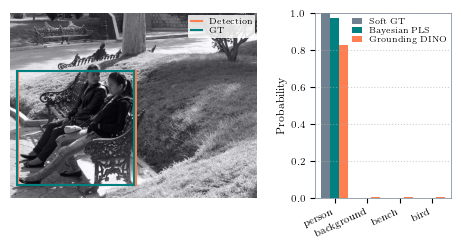

  [agree-0] image_id=227478 row=34341  GT=person  Ours=person  GDino=person


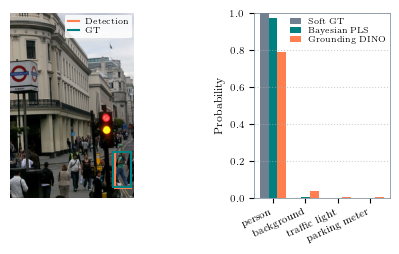

  [agree-1] image_id=412894 row=61439  GT=person  Ours=person  GDino=person


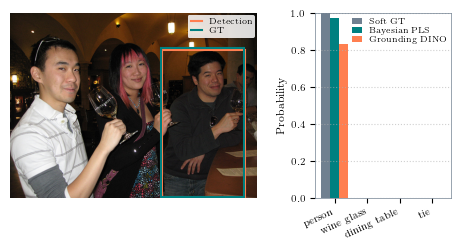

  [agree-2] image_id=442161 row=66045  GT=person  Ours=person  GDino=person


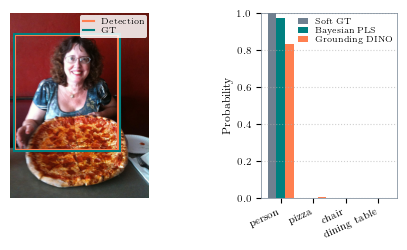

  [agree-3] image_id=306700 row=46144  GT=person  Ours=person  GDino=person


In [6]:
for i, idx in enumerate(agree_examples):
    plot_example(idx, f"agree-{i}", f"plots/examples/agreement_{i}.png")

### Disagreement examples

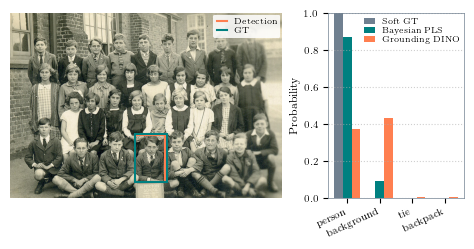

  [disagree-0] image_id=390555 row=58465  GT=person  Ours=person  GDino=background


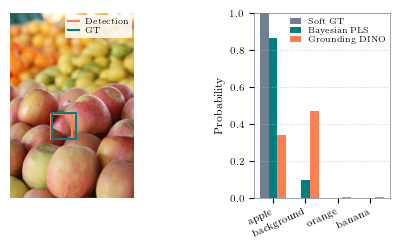

  [disagree-1] image_id=406570 row=60558  GT=apple  Ours=apple  GDino=background


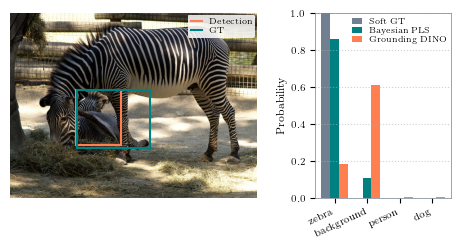

  [disagree-2] image_id=104455 row=15029  GT=zebra  Ours=zebra  GDino=background


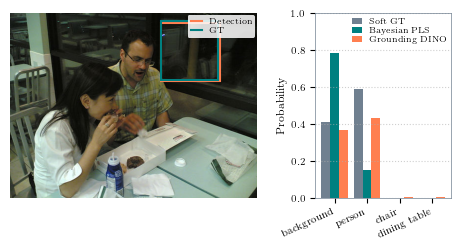

  [disagree-3] image_id=69224 row=10397  GT=person  Ours=background  GDino=person


In [7]:
for i, idx in enumerate(disagree_examples):
    plot_example(idx, f"disagree-{i}", f"plots/examples/disagreement_{i}.png")

### Uncertain ground truth examples

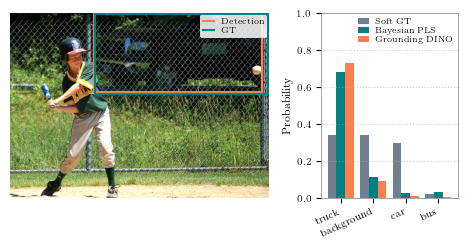

  [uncertain_gt-0] image_id=33759 row=5510  GT=truck  Ours=truck  GDino=truck


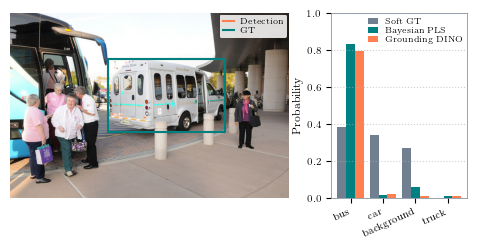

  [uncertain_gt-1] image_id=507797 row=75822  GT=bus  Ours=bus  GDino=bus


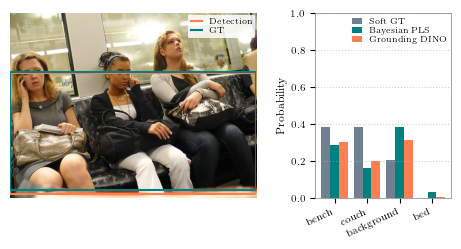

  [uncertain_gt-2] image_id=398377 row=59540  GT=bench  Ours=background  GDino=background


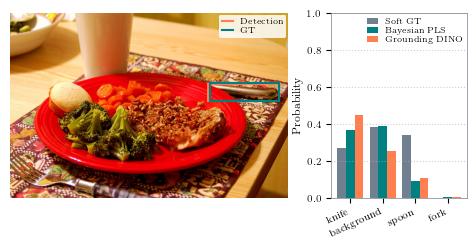

  [uncertain_gt-3] image_id=460494 row=68455  GT=background  Ours=background  GDino=knife


In [8]:
for i, idx in enumerate(uncertain_gt_examples):
    plot_example(idx, f"uncertain_gt-{i}", f"plots/examples/uncertain_gt_{i}.png")